# Diagnosis kerusakan bearing: dari data mentah sampai model

Kasus 04, proyek kelompok Machine Learning MKB UPI (P4–P5).

Klien kita analis getaran di pabrik semen. Ia ingin rekaman getaran yang sudah diringkas bisa langsung
diklasifikasikan menjadi `normal`, `outer_race`, `inner_race`, atau `bola`, supaya teknisi tahu suku cadang
apa yang harus disiapkan. Metrik utama dari *brief* adalah *macro* F1, dan *baseline* wajibnya regresi
logistik multikelas dengan fitur asli.

Urutan notebook ini:

1. memuat data dan mencari masalah data,
2. membersihkan data,
3. EDA,
4. membagi data secara *stratified* menjadi *train* (70%), *validation* (15%), dan *test* (15%),
5. melatih *baseline* dan model pembanding, lalu memilih model dengan data *validation*,
6. membuka data *test* satu kali di akhir,
7. menyimpan `artifacts/model.joblib` dan `artifacts/metadata.json`.

Notebook dapat dijalankan dari folder `notebooks/` maupun dari akar repositori.

In [1]:
from pathlib import Path
import sys, json, platform, datetime

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score)
from sklearn.inspection import permutation_importance

from src.features import (CLASSES, NUM_COLS, CAT_COLS, RAW_FEATURES, ENGINEERED, MODEL_FEATURES,
                          RENTANG_WAJAR, SUKU_CADANG, clean_raw, add_features,
                          make_preprocessor, feature_step, normalize_label)

RANDOM_STATE = 42
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
print("python", platform.python_version(), "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

python 3.13.18 | pandas 3.0.5 | sklearn 1.9.1


## 1. Memuat data dan mencari masalah

In [2]:
df_raw = pd.read_csv(ROOT / "data" / "raw.csv")
print(df_raw.shape)
df_raw.head()

(15220, 14)


,id_rekaman,posisi_sensor,kecepatan_rpm,beban_kN,suhu_housing_C,rms_g,puncak_g,kurtosis,crest_factor,energi_bpfo,energi_bpfi,energi_bsf,frekuensi_dominan_hz,kondisi
0,REC-06504,drive_end,2547.0,2.79,53.8,0.5168,1.1658,0.039,2.256,0.1400,0.0436,0.0629,40.9,NORMAL
1,REC-02314,drive_end,1824.0,0.54,47.9,0.3603,1.1888,2.109,3.300,0.1309,0.0031,0.1030,116.0,outer
2,REC-01359,drive_end,2865.0,3.72,53.7,0.6982,2.0926,1.224,2.997,0.1902,0.0680,0.1525,46.5,normal
3,REC-12268,drive_end,2796.0,1.15,51.8,0.4973,1.4369,2.706,2.890,0.0788,0.0662,0.0441,46.4,normal
4,REC-06543,fan_end,2419.0,2.09,55.3,0.5089,1.6455,2.894,3.234,0.0230,0.0045,0.1951,82.7,bola


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 15220 entries, 0 to 15219
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_rekaman            15220 non-null  str    
 1   posisi_sensor         15220 non-null  str    
 2   kecepatan_rpm         15220 non-null  float64
 3   beban_kN              15220 non-null  float64
 4   suhu_housing_C        15067 non-null  float64
 5   rms_g                 15220 non-null  float64
 6   puncak_g              15220 non-null  float64
 7   kurtosis              14764 non-null  float64
 8   crest_factor          15220 non-null  float64
 9   energi_bpfo           15220 non-null  float64
 10  energi_bpfi           15220 non-null  float64
 11  energi_bsf            15220 non-null  float64
 12  frekuensi_dominan_hz  15220 non-null  float64
 13  kondisi               15220 non-null  str    
dtypes: float64(11), str(3)
memory usage: 2.0 MB


In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
kecepatan_rpm,15220.0,2090.959461,533.368985,0.0000,1644.000000,2095.50000,2546.000000,3000.0000
beban_kN,15220.0,3.243971,1.584132,0.5000,1.860000,3.23000,4.620000,6.0000
suhu_housing_C,15067.0,52.747946,4.218667,39.2000,49.800000,52.70000,55.600000,67.9000
rms_g,15220.0,0.480142,0.147388,-0.9521,0.377300,0.46945,0.572625,1.0992
puncak_g,15220.0,1.611779,0.533721,0.4632,1.216675,1.54330,1.932200,4.3333
kurtosis,14764.0,3.364824,0.967957,0.0330,2.698000,3.32850,3.988000,7.2270
crest_factor,15220.0,3.324770,0.450251,1.7240,3.023000,3.31400,3.623000,5.1170
energi_bpfo,15220.0,0.100026,0.082510,0.0000,0.040800,0.08040,0.135400,0.6983
energi_bpfi,15220.0,0.081615,0.067608,0.0000,0.031400,0.06590,0.113025,0.4994
energi_bsf,15220.0,0.073259,0.056650,0.0000,0.029900,0.06140,0.103300,0.4314


Beberapa hal langsung terlihat dari ringkasan di atas: `kecepatan_rpm` punya nilai minimum 0, `rms_g` punya
nilai negatif (besar getaran tidak mungkin negatif), dan ada kolom yang jumlah barisnya kurang dari 15.220.
Label target juga perlu dicek.

In [5]:
df_raw["kondisi"].value_counts()

kondisi
normal        7863
outer_race    2894
inner_race    2072
bola          1476
ok             164
NORMAL         154
Normal         150
outer           72
Outer Race      67
IR              57
OR              55
BALL            43
inner           43
Inner Race      41
ball            39
Bola            30
Name: count, dtype: int64

Label ditulis dalam 16 variasi (`NORMAL`, `ok`, `OR`, `Outer Race`, `BALL`, dan seterusnya) padahal kelasnya
hanya empat. Kalau tidak diseragamkan, model akan menganggap `OR` dan `outer_race` sebagai dua kelas berbeda.

Untuk `rms_g` negatif, kita cek apakah besarnya masih benar. *Crest factor* didefinisikan sebagai puncak
dibagi RMS, jadi kalau `puncak_g / |rms_g|` sama dengan `crest_factor`, berarti hanya tandanya yang salah.

In [6]:
neg = df_raw[df_raw["rms_g"] < 0]
selisih = (neg["puncak_g"] / neg["rms_g"].abs() - neg["crest_factor"]).abs()
print("baris rms_g negatif:", len(neg))
print("selisih maksimum puncak/|rms| terhadap crest_factor:", round(selisih.max(), 4))

baris rms_g negatif: 45
selisih maksimum puncak/|rms| terhadap crest_factor: 0.0008


Selisihnya hanya sisa pembulatan, jadi `rms_g` negatif cukup diambil nilai mutlaknya.

`kecepatan_rpm = 0` lain ceritanya. Motor yang diam tidak mungkin menghasilkan getaran dengan frekuensi dominan
puluhan hertz, jadi angka 0 itu kemungkinan besar sensor kecepatan yang gagal membaca. Nilainya kita anggap
hilang dan diisi median oleh imputer di dalam *pipeline*.

In [7]:
rpm0 = df_raw[df_raw["kecepatan_rpm"] == 0]
rpm0[["kecepatan_rpm", "frekuensi_dominan_hz", "rms_g", "kondisi"]].head()

,kecepatan_rpm,frekuensi_dominan_hz,rms_g,kondisi
424,0.0,90.4,0.5673,normal
447,0.0,47.5,0.5453,normal
1102,0.0,96.1,0.7921,inner_race
1151,0.0,37.1,0.3854,normal
1389,0.0,43.1,0.6859,normal


In [8]:
label_baku = df_raw["kondisi"].astype(str).str.strip().isin(CLASSES)
masalah = pd.DataFrame([
    ["Baris duplikat persis (id_rekaman ikut sama)", int(df_raw.duplicated().sum()),
     "Dihapus dengan drop_duplicates", "Rekaman yang sama terekspor dua kali; kalau dibiarkan bisa masuk train dan test sekaligus"],
    ["Label target tidak baku (16 variasi tulisan)", int((~label_baku).sum()),
     "Dipetakan ke 4 kelas baku", "OR, outer, Outer Race artinya sama"],
    ["suhu_housing_C kosong", int(df_raw["suhu_housing_C"].isna().sum()),
     "Diisi median data train (imputer di pipeline)", "Kosongnya merata di semua kelas, jadi tidak membawa informasi"],
    ["kurtosis kosong", int(df_raw["kurtosis"].isna().sum()),
     "Diisi median data train (imputer di pipeline)", "Sama seperti di atas"],
    ["kecepatan_rpm = 0", int((df_raw["kecepatan_rpm"] == 0).sum()),
     "Dijadikan kosong, lalu diisi median data train", "Mustahil: motor diam tidak punya frekuensi dominan puluhan Hz"],
    ["rms_g negatif", int((df_raw["rms_g"] < 0).sum()),
     "Diambil nilai mutlaknya", "puncak_g / |rms_g| tetap cocok dengan crest_factor"],
], columns=["Masalah", "Jumlah baris (data mentah)", "Penanganan", "Alasan"])
masalah

,Masalah,Jumlah baris (data mentah),Penanganan,Alasan
0,Baris duplikat persis (id_rekaman ikut sama),220,Dihapus dengan drop_duplicates,Rekaman yang sama terekspor dua kali; kalau di...
1,Label target tidak baku (16 variasi tulisan),915,Dipetakan ke 4 kelas baku,"OR, outer, Outer Race artinya sama"
2,suhu_housing_C kosong,153,Diisi median data train (imputer di pipeline),"Kosongnya merata di semua kelas, jadi tidak me..."
3,kurtosis kosong,456,Diisi median data train (imputer di pipeline),Sama seperti di atas
4,kecepatan_rpm = 0,61,"Dijadikan kosong, lalu diisi median data train",Mustahil: motor diam tidak punya frekuensi dom...
5,rms_g negatif,45,Diambil nilai mutlaknya,puncak_g / |rms_g| tetap cocok dengan crest_fa...


In [9]:
# Apakah data kosong lebih sering muncul di kelas tertentu? (kalau ya, kosongnya sendiri bisa jadi informasi)
tmp = df_raw.assign(kelas=normalize_label(df_raw["kondisi"]))
tmp.groupby("kelas")[["suhu_housing_C", "kurtosis"]].apply(lambda g: g.isna().mean().round(3))

,suhu_housing_C,kurtosis
kelas,,
bola,0.011,0.030
inner_race,0.010,0.025
normal,0.009,0.030
outer_race,0.012,0.032


## 2. Membersihkan data

In [10]:
df, log_bersih = clean_raw(df_raw)
print(json.dumps(log_bersih, indent=2))
print("ukuran setelah dibersihkan:", df.shape)
df["kondisi"].value_counts()

{
  "duplikat_dihapus": 220,
  "label_tidak_baku": 900,
  "label_tidak_dikenal_dibuang": 0,
  "rms_negatif_diperbaiki": 45,
  "rpm_nol_dijadikan_kosong": 60,
  "suhu_kosong": 150,
  "kurtosis_kosong": 450
}
ukuran setelah dibersihkan: (15000, 14)


kondisi
normal        8219
outer_race    3039
inner_race    2178
bola          1564
Name: count, dtype: int64

Pengisian nilai kosong sengaja tidak dilakukan di sini. Imputer ada di dalam *pipeline* model, jadi median
dihitung dari data *train* saja dan data *validation*/*test* tidak ikut "bocor" ke statistik itu.

## 3. EDA

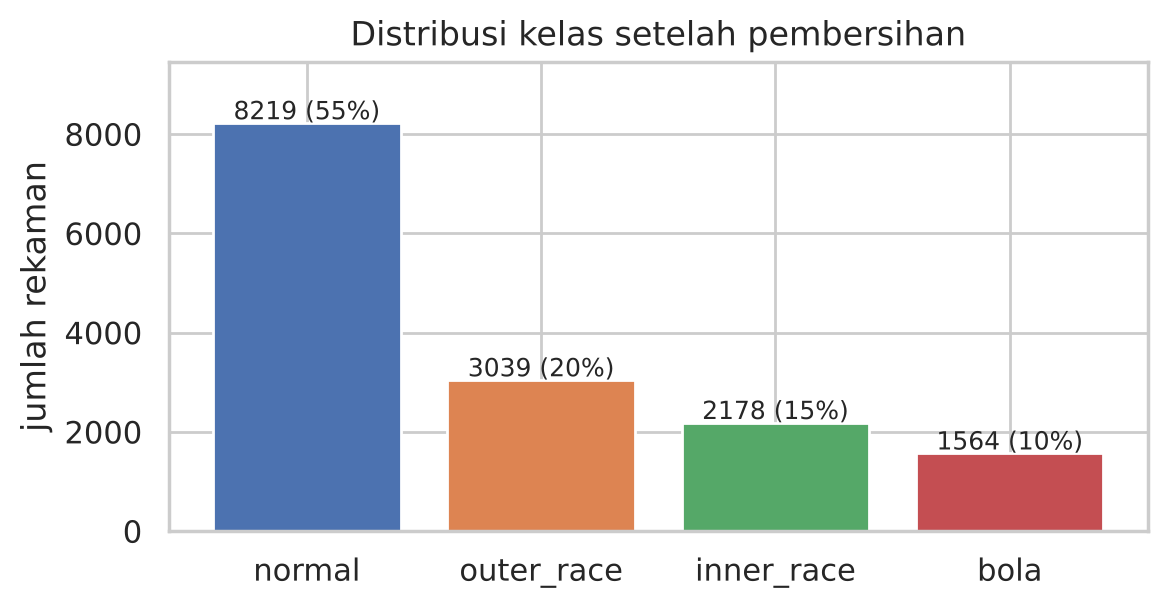

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.2))
vc = df["kondisi"].value_counts().reindex(CLASSES)
ax.bar(vc.index, vc.values, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
for i, v in enumerate(vc.values):
    ax.text(i, v + 80, f"{v} ({v / len(df):.0%})", ha="center", fontsize=9)
ax.set_title("Distribusi kelas setelah pembersihan")
ax.set_ylabel("jumlah rekaman")
ax.set_ylim(0, vc.max() * 1.15)
plt.tight_layout(); plt.savefig(FIG / "fig01_distribusi_kelas.png", dpi=150); plt.show()

Kelas tidak seimbang: `normal` lebih dari separuh data, `bola` hanya sekitar 10%. Ini alasan *brief* memakai
*macro* F1. Akurasi bisa tinggi hanya dengan menebak `normal`, sedangkan *macro* F1 memberi bobot sama untuk
keempat kelas.

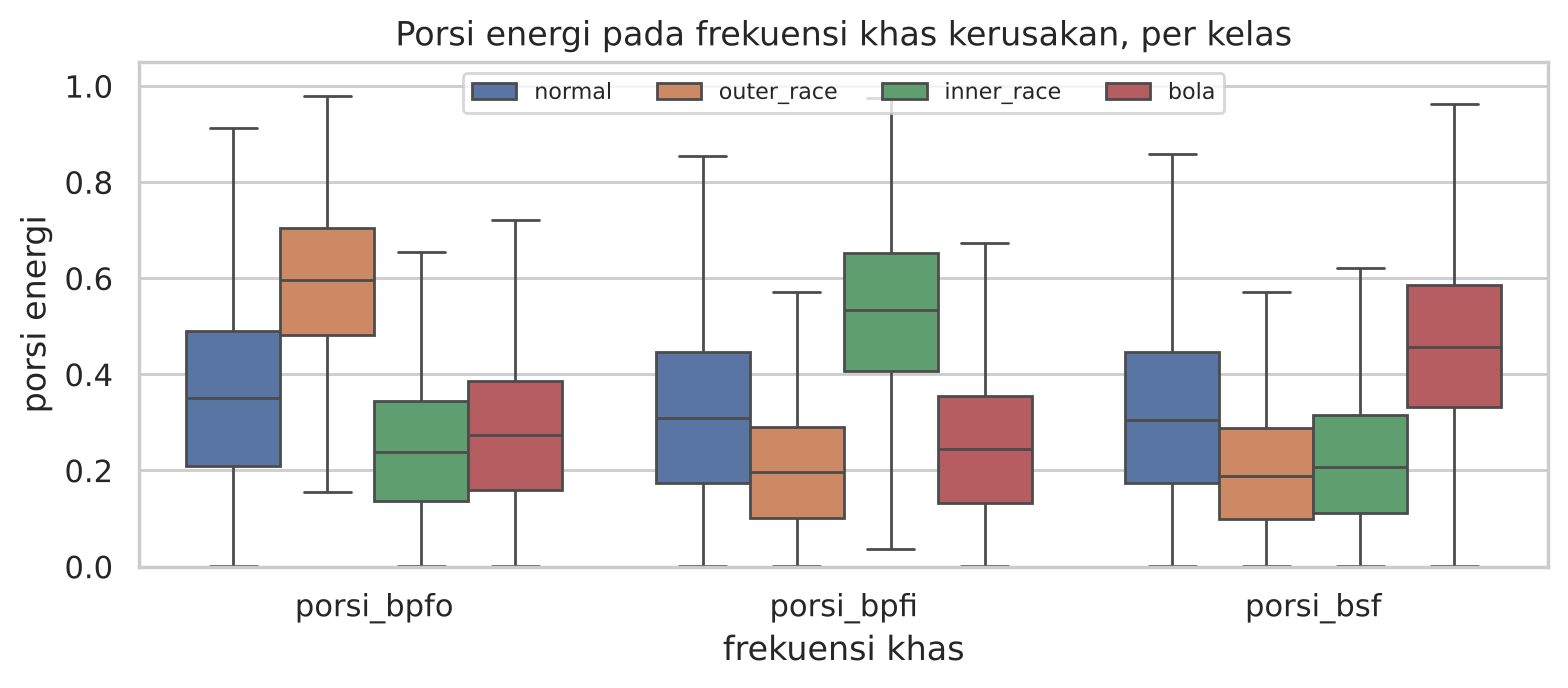

In [12]:
fe = add_features(df[RAW_FEATURES]).assign(kondisi=df["kondisi"])
porsi = fe.melt(id_vars="kondisi", value_vars=["porsi_bpfo", "porsi_bpfi", "porsi_bsf"],
                var_name="frekuensi khas", value_name="porsi energi")
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.boxplot(data=porsi, x="frekuensi khas", y="porsi energi", hue="kondisi", hue_order=CLASSES,
            showfliers=False, ax=ax)
ax.set_title("Porsi energi pada frekuensi khas kerusakan, per kelas")
ax.legend(ncol=4, fontsize=8, loc="upper center")
ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.savefig(FIG / "fig02_porsi_energi.png", dpi=150); plt.show()

Temuan pertama: setiap jenis kerusakan menonjol di frekuensi khasnya sendiri. Rekaman `outer_race` punya porsi
energi BPFO paling besar, `inner_race` di BPFI, dan `bola` di BSF. Rekaman normal tersebar merata. Porsi lebih
mudah dibaca daripada energi mentah karena tidak ikut naik-turun dengan besar getaran keseluruhan.

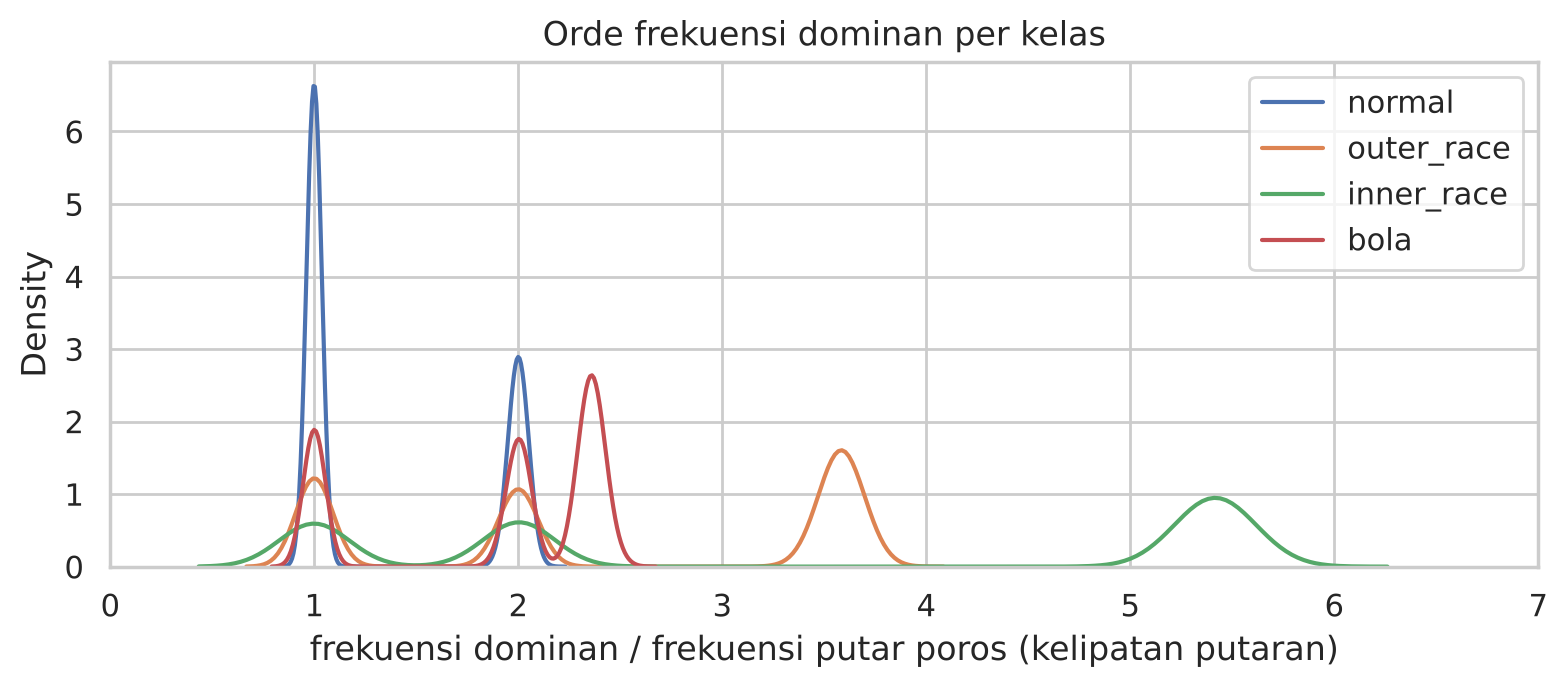

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for k in CLASSES:
    sns.kdeplot(fe.loc[fe["kondisi"] == k, "orde_frekuensi"].dropna(), ax=ax, label=k, bw_adjust=0.4, fill=False)
ax.set_xlim(0, 7)
ax.set_xlabel("frekuensi dominan / frekuensi putar poros (kelipatan putaran)")
ax.set_title("Orde frekuensi dominan per kelas")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "fig03_orde_frekuensi.png", dpi=150); plt.show()

Temuan kedua: kalau frekuensi dominan dibagi frekuensi putar poros (rpm/60), puncaknya mengumpul di kelipatan
yang khas. Rekaman normal ada di sekitar 1× dan 2× putaran (getaran poros biasa), `bola` di sekitar 2,3×,
`outer_race` di sekitar 3,6×, dan `inner_race` di sekitar 5,4×. Sebagian rekaman rusak tetap punya frekuensi
dominan di 1× atau 2×, dan di situlah model akan sering keliru. Karena itu fitur `orde_frekuensi` kita buat.

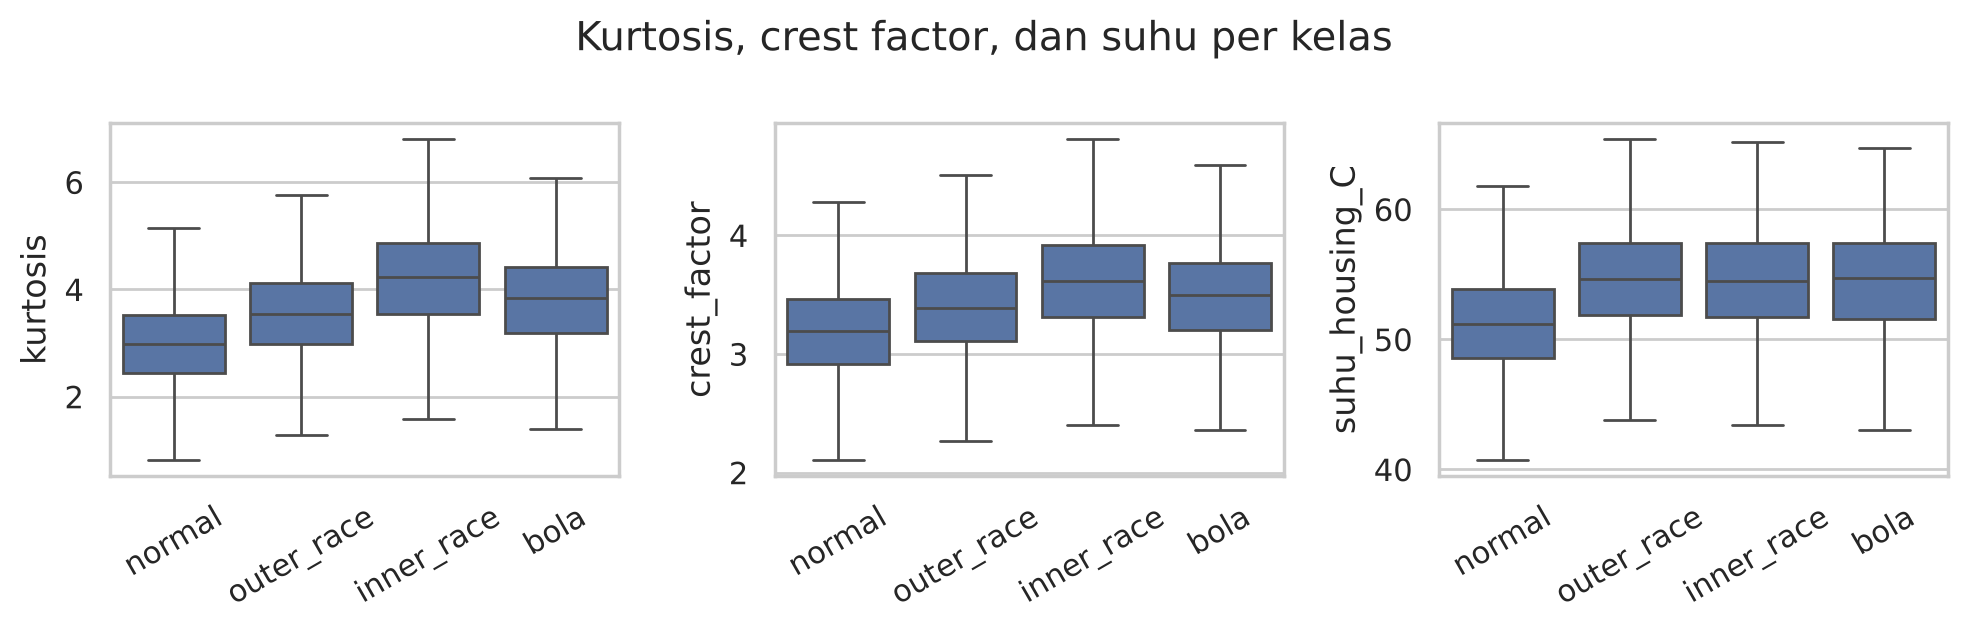

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, col in zip(axes, ["kurtosis", "crest_factor", "suhu_housing_C"]):
    sns.boxplot(data=df, x="kondisi", y=col, order=CLASSES, showfliers=False, ax=ax)
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
plt.suptitle("Kurtosis, crest factor, dan suhu per kelas")
plt.tight_layout(); plt.savefig(FIG / "fig04_kurtosis_suhu.png", dpi=150); plt.show()

Temuan ketiga: kurtosis, *crest factor*, dan suhu rumah *bearing* lebih tinggi pada ketiga kelas rusak
dibandingkan normal, tetapi rentangnya saling tumpang tindih. Fitur-fitur ini membantu memisahkan normal dari
rusak, tetapi kurang membantu membedakan jenis kerusakannya.

## 4. Membagi data

In [15]:
X = df[RAW_FEATURES]
y = df["kondisi"]
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)

pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).reindex(CLASSES).round(3).T.assign(jumlah_baris=[len(y_train), len(y_val), len(y_test)])

kondisi,normal,outer_race,inner_race,bola,jumlah_baris
train,0.548,0.203,0.145,0.104,10500
validation,0.548,0.203,0.145,0.104,2250
test,0.548,0.203,0.145,0.104,2250


Pembagiannya acak *stratified* sesuai *brief*. Setiap rekaman berdiri sendiri (tidak ada urutan waktu dan
tidak ada kolom identitas motor), jadi pembagian berdasarkan waktu atau kelompok tidak diperlukan. Duplikat
sudah dihapus sebelum pembagian, sehingga rekaman yang sama tidak bisa muncul di *train* dan *test* sekaligus.

Data *test* tidak disentuh sampai bagian 6.

## 5. *Baseline* dan model pembanding (dinilai dengan data *validation*)

In [16]:
def logreg_baseline():
    # Baseline wajib: regresi logistik multikelas dengan fitur asli saja.
    return Pipeline([
        ("prep", make_preprocessor(NUM_COLS, scale=True)),
        ("clf", LogisticRegression(max_iter=2000)),
    ])

def dengan_fitur(clf, scale=False):
    return Pipeline([
        ("fe", feature_step()),
        ("prep", make_preprocessor(NUM_COLS + ENGINEERED, scale=scale)),
        ("clf", clf),
    ])

kandidat = {
    "Baseline: regresi logistik (fitur asli)": logreg_baseline(),
    "Regresi logistik + fitur turunan": dengan_fitur(LogisticRegression(max_iter=3000), scale=True),
    "Random forest + fitur turunan": dengan_fitur(RandomForestClassifier(
        n_estimators=500, min_samples_leaf=3, max_features=0.5, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE)),
    "HistGradientBoosting (fitur asli)": Pipeline([
        ("prep", make_preprocessor(NUM_COLS, scale=False)),
        ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=800, min_samples_leaf=40,
                                               l2_regularization=1.0, random_state=RANDOM_STATE))]),
    "HistGradientBoosting + fitur turunan": dengan_fitur(HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=800, min_samples_leaf=40, l2_regularization=1.0, random_state=RANDOM_STATE)),
    "HistGradientBoosting + fitur turunan (class_weight balanced)": dengan_fitur(HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=800, min_samples_leaf=40, l2_regularization=1.0,
        class_weight="balanced", random_state=RANDOM_STATE)),
}

baris = []
for nama, model in kandidat.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    f1_kelas = f1_score(y_val, pred, average=None, labels=CLASSES)
    baris.append({"model": nama, "macro_F1_val": f1_score(y_val, pred, average="macro"),
                  "akurasi_val": accuracy_score(y_val, pred),
                  **{f"F1_{k}": v for k, v in zip(CLASSES, f1_kelas)}})

hasil_val = pd.DataFrame(baris).sort_values("macro_F1_val", ascending=False).reset_index(drop=True)
hasil_val.to_csv(ROOT / "reports" / "hasil_validation.csv", index=False)
hasil_val.round(4)

,model,macro_F1_val,akurasi_val,F1_normal,F1_outer_race,F1_inner_race,F1_bola
0,HistGradientBoosting + fitur turunan,0.8197,0.8596,0.8986,0.8264,0.8228,0.7309
1,Random forest + fitur turunan,0.8057,0.8418,0.8785,0.8010,0.8130,0.7304
2,HistGradientBoosting (fitur asli),0.7997,0.8484,0.8946,0.8118,0.8177,0.6748
3,HistGradientBoosting + fitur turunan (class_we...,0.7870,0.8249,0.8711,0.8009,0.7829,0.6933
4,Regresi logistik + fitur turunan,0.7309,0.8067,0.8809,0.7347,0.7536,0.5544
5,Baseline: regresi logistik (fitur asli),0.7247,0.8031,0.8789,0.7355,0.7412,0.5431


In [17]:
nama_baseline = "Baseline: regresi logistik (fitur asli)"
nama_final = hasil_val.loc[0, "model"]
f1_base_val = hasil_val.set_index("model").loc[nama_baseline, "macro_F1_val"]
f1_final_val = hasil_val.loc[0, "macro_F1_val"]
print("model terpilih:", nama_final)
print(f"macro F1 validation: baseline {f1_base_val:.4f} -> final {f1_final_val:.4f} (+{f1_final_val - f1_base_val:.4f})")
print()
print(classification_report(y_val, kandidat[nama_final].predict(X_val), labels=CLASSES, digits=3))

model terpilih: HistGradientBoosting + fitur turunan
macro F1 validation: baseline 0.7247 -> final 0.8197 (+0.0950)

              precision    recall  f1-score   support

      normal      0.845     0.959     0.899      1233
  outer_race      0.895     0.768     0.826       456
  inner_race      0.878     0.774     0.823       327
        bola      0.865     0.632     0.731       234

    accuracy                          0.860      2250
   macro avg      0.871     0.783     0.820      2250
weighted avg      0.862     0.860     0.856      2250



Model berbasis pohon jauh mengungguli regresi logistik. Masuk akal: hubungan antara orde frekuensi dan kelas
tidak linier (kelas yang sama muncul di beberapa kelipatan putaran), dan regresi logistik hanya bisa menarik
batas lurus. Menambahkan fitur turunan ke regresi logistik justru tidak membantu karena alasan yang sama.

`class_weight="balanced"` menurunkan *macro* F1 di *validation*. Bobot itu membuat model lebih sering menebak
kelas kecil, sehingga *precision* kelas kecil turun lebih banyak daripada kenaikan *recall*-nya. Jadi model
final tidak memakai pembobotan kelas.

Catatan jujur: enam konfigurasi dibandingkan di data *validation* yang sama, sehingga skor *validation* model
terpilih sedikit optimistis. Data *test* di bagian 6 adalah ukuran yang tidak bias.

### Ambang keyakinan

Ini klasifikasi multikelas, jadi keputusan dasarnya adalah kelas dengan probabilitas tertinggi (*argmax*),
bukan *threshold* ya/tidak. Tetapi teknisi perlu tahu kapan tebakan model meragukan. Kita pilih ambang
keyakinan: jika probabilitas tertinggi di bawah ambang, aplikasi tetap menampilkan tebakan, tetapi menandainya
"perlu dicek analis getaran". Ambang dipilih dari data *validation*: nilai terkecil yang membuat tebakan
yang lolos ambang benar minimal 90%.

In [18]:
model_val = kandidat[nama_final]
proba_val = model_val.predict_proba(X_val)
kelas_model = list(model_val.classes_)
pred_val = np.array(kelas_model)[proba_val.argmax(1)]
maks = proba_val.max(1)

tabel_ambang = []
for t in np.round(np.arange(0.40, 0.96, 0.05), 2):
    lolos = maks >= t
    tabel_ambang.append({"ambang": t, "porsi_otomatis": lolos.mean(),
                         "akurasi_yang_lolos": (pred_val[lolos] == y_val.values[lolos]).mean(),
                         "macro_F1_yang_lolos": f1_score(y_val.values[lolos], pred_val[lolos], average="macro")})
tabel_ambang = pd.DataFrame(tabel_ambang)
AMBANG = float(tabel_ambang.loc[tabel_ambang["akurasi_yang_lolos"] >= 0.90, "ambang"].min())
print("ambang keyakinan terpilih:", AMBANG)
tabel_ambang.round(3)

ambang keyakinan terpilih: 0.65


,ambang,porsi_otomatis,akurasi_yang_lolos,macro_F1_yang_lolos
0,0.40,0.989,0.865,0.827
1,0.45,0.979,0.869,0.833
2,0.50,0.957,0.878,0.844
3,0.55,0.926,0.887,0.855
4,0.60,0.891,0.898,0.869
5,0.65,0.860,0.906,0.880
6,0.70,0.821,0.914,0.892
7,0.75,0.786,0.924,0.904
8,0.80,0.731,0.934,0.918
9,0.85,0.661,0.944,0.934


### Fitur yang paling berpengaruh

*Permutation importance* dihitung pada data *validation*: satu fitur diacak, lalu dilihat seberapa jauh
*macro* F1 turun. Semakin besar penurunannya, semakin model bergantung pada fitur itu.

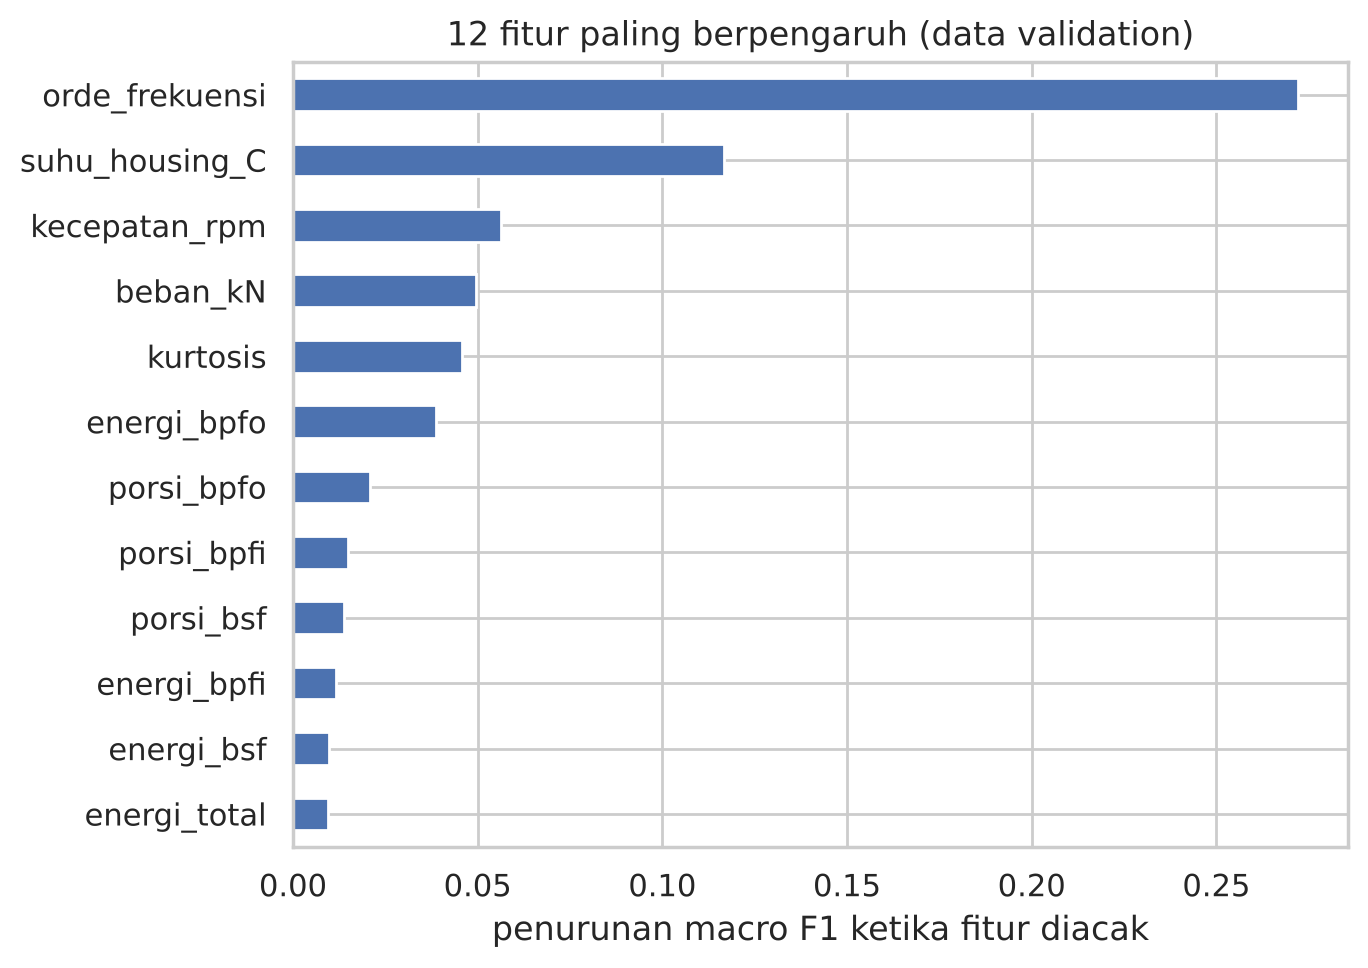

orde_frekuensi    0.2720
suhu_housing_C    0.1166
kecepatan_rpm     0.0563
beban_kN          0.0495
kurtosis          0.0459
energi_bpfo       0.0388
porsi_bpfo        0.0208
porsi_bpfi        0.0150
porsi_bsf         0.0139
energi_bpfi       0.0116
energi_bsf        0.0097
energi_total      0.0094
dtype: float64

In [19]:
fe_step = model_val[:-1]
Xv_t = fe_step.transform(X_val)
nama_fitur = [n.split("__", 1)[1] for n in model_val.named_steps["prep"].get_feature_names_out()]
pi = permutation_importance(model_val.named_steps["clf"], Xv_t, y_val, scoring="f1_macro",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=nama_fitur).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 5))
imp.tail(12).plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("penurunan macro F1 ketika fitur diacak")
ax.set_title("12 fitur paling berpengaruh (data validation)")
plt.tight_layout(); plt.savefig(FIG / "fig05_permutation_importance.png", dpi=150); plt.show()
imp.sort_values(ascending=False).round(4).head(12)

`orde_frekuensi` jauh di atas fitur lain. Ini sejalan dengan cara analis getaran membaca spektrum: di
kelipatan putaran berapa getaran terbesar muncul. Fitur ini dibuat sendiri dari dua kolom asli. Tanpa fitur
turunan, model *gradient boosting* yang sama hanya mencapai *macro* F1 sekitar 0,80 di *validation*.

Urutan kedua adalah `suhu_housing_C`, disusul `kecepatan_rpm` dan `beban_kN`. Dari EDA, median suhu *bearing* rusak
sekitar 3 °C lebih tinggi daripada yang normal. Suhu juga naik karena beban dan kecepatan, jadi kemungkinan
model memakai ketiganya bersama-sama untuk menilai apakah suhu lebih tinggi dari yang wajar untuk kondisi
operasi tersebut. Ini dugaan dari pola *importance*, belum dibuktikan. Kesalahan terbesar model adalah
rekaman rusak yang ditebak normal, sehingga fitur yang membantu memisahkan rusak dari normal memang paling
berpengaruh terhadap *macro* F1.

Fitur energi dan porsi energi berpengaruh lebih kecil per fitur, karena informasinya terbagi ke enam kolom
yang saling berkaitan. Kalau satu kolom diacak, kolom lain masih membawa informasi yang mirip.

## 6. Data *test* (dibuka satu kali)

Model final dan *baseline* dilatih ulang dengan gabungan *train* + *validation*. Pilihan model, parameter, dan
ambang keyakinan tidak diubah lagi setelah sel ini dijalankan.

In [20]:
X_trval = pd.concat([X_train, X_val]); y_trval = pd.concat([y_train, y_val])

model_final = sklearn.base.clone(kandidat[nama_final]).fit(X_trval, y_trval)
model_base = sklearn.base.clone(kandidat[nama_baseline]).fit(X_trval, y_trval)

pred_test = model_final.predict(X_test)
pred_test_base = model_base.predict(X_test)
f1_final_test = f1_score(y_test, pred_test, average="macro")
f1_base_test = f1_score(y_test, pred_test_base, average="macro")
print(f"macro F1 test: baseline {f1_base_test:.4f} | final {f1_final_test:.4f}")
print()
print(classification_report(y_test, pred_test, labels=CLASSES, digits=3))

macro F1 test: baseline 0.7466 | final 0.7991

              precision    recall  f1-score   support

      normal      0.835     0.950     0.888      1233
  outer_race      0.894     0.781     0.834       456
  inner_race      0.868     0.709     0.780       326
        bola      0.792     0.617     0.694       235

    accuracy                          0.846      2250
   macro avg      0.847     0.764     0.799      2250
weighted avg      0.847     0.846     0.841      2250



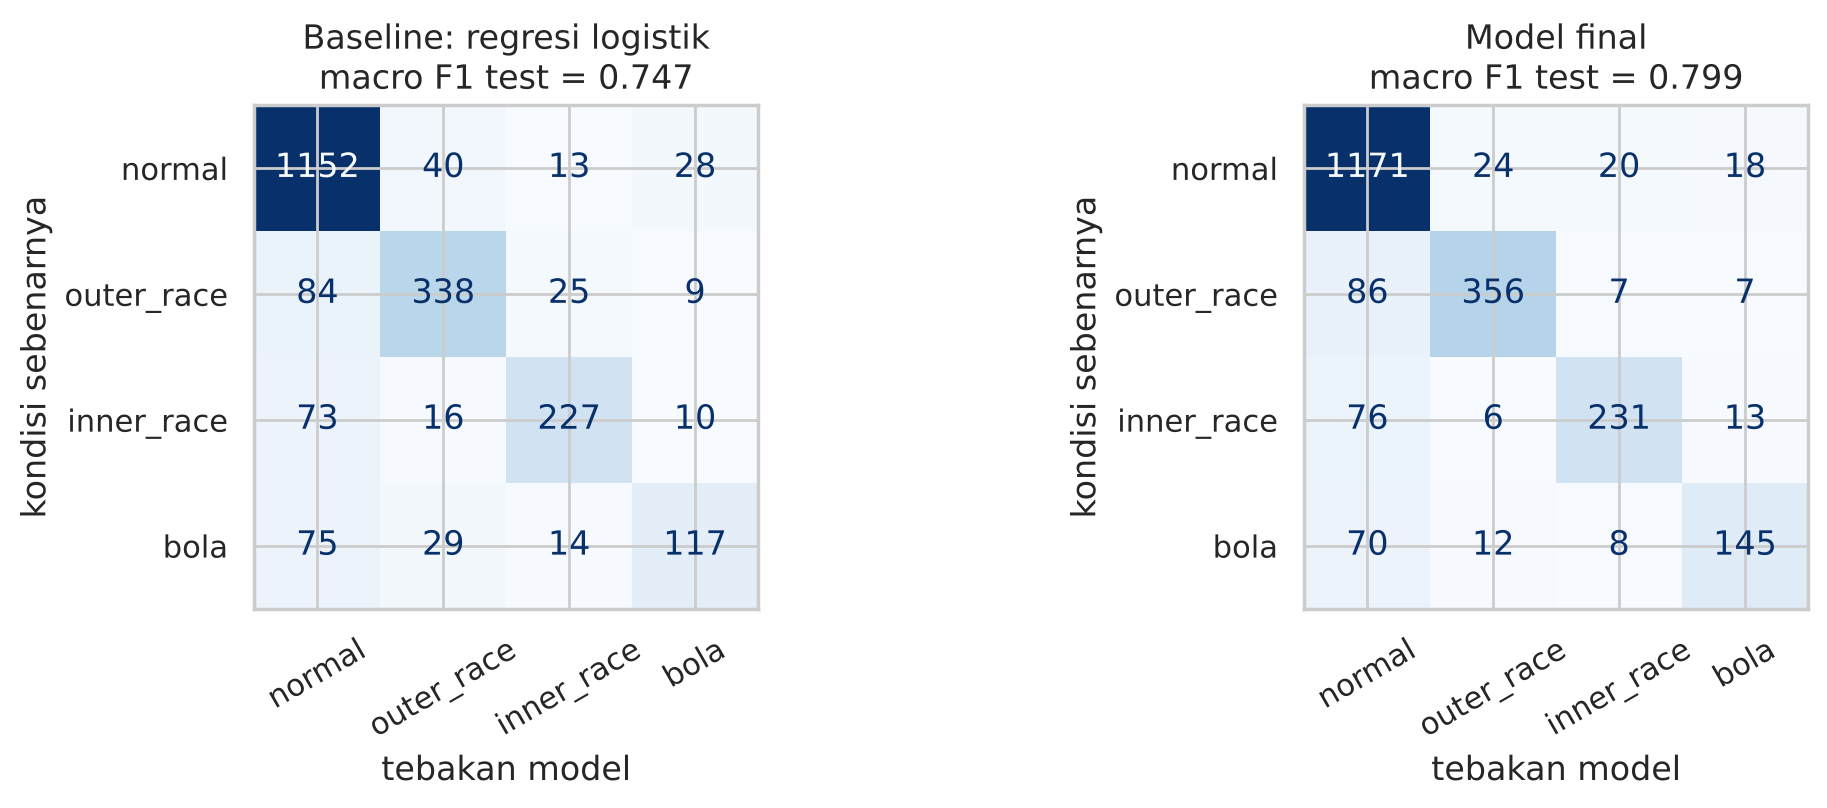

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (judul, pred) in zip(axes, [("Baseline: regresi logistik", pred_test_base), ("Model final", pred_test)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=CLASSES), display_labels=CLASSES).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(f"{judul}\nmacro F1 test = {f1_score(y_test, pred, average='macro'):.3f}")
    ax.set_xlabel("tebakan model"); ax.set_ylabel("kondisi sebenarnya"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG / "fig06_confusion_matrix_test.png", dpi=150); plt.show()

In [22]:
cm = pd.DataFrame(confusion_matrix(y_test, pred_test, labels=CLASSES), index=CLASSES, columns=CLASSES)
salah = cm.where(~np.eye(len(CLASSES), dtype=bool)).stack().sort_values(ascending=False)
print("pasangan yang paling sering tertukar (sebenarnya -> tebakan):")
print(salah.head(5).astype(int))

proba_test = model_final.predict_proba(X_test)
lolos = proba_test.max(1) >= AMBANG
print()
print(f"rekaman test dengan keyakinan >= {AMBANG}: {lolos.mean():.1%}, akurasinya {(pred_test[lolos] == y_test.values[lolos]).mean():.3f}")
print(f"rekaman yang ditandai 'perlu dicek analis': {(~lolos).mean():.1%}, akurasinya {(pred_test[~lolos] == y_test.values[~lolos]).mean():.3f}")

pasangan yang paling sering tertukar (sebenarnya -> tebakan):
outer_race  normal        86
inner_race  normal        76
bola        normal        70
normal      outer_race    24
            inner_race    20
dtype: int64

rekaman test dengan keyakinan >= 0.65: 84.8%, akurasinya 0.905
rekaman yang ditandai 'perlu dicek analis': 15.2%, akurasinya 0.516


Di data *test*, model final mencapai *macro* F1 0,799, naik dari 0,747 milik *baseline*. Skor ini sedikit di
bawah skor *validation* (0,820), sesuai dugaan bahwa skor *validation* agak optimistis karena dipakai untuk
memilih model.

*Confusion matrix* menunjukkan pola kesalahan yang jelas: hampir semua kesalahan berupa *bearing* rusak yang
ditebak normal (`outer_race`, `inner_race`, dan `bola` yang tertebak `normal`). Ini cocok dengan grafik orde
frekuensi: sebagian rekaman rusak punya frekuensi dominan di 1× atau 2× putaran, sama seperti rekaman normal.
Antar jenis kerusakan sendiri jarang tertukar. Kelas `bola` paling lemah (F1 0,69) karena datanya paling
sedikit dan puncak 2,3×-nya dekat dengan puncak 2× milik rekaman normal.

Bagi teknisi, kesalahan "rusak ditebak normal" lebih mahal daripada sebaliknya, karena *bearing* yang rusak
tetap dipakai. Itulah gunanya ambang keyakinan: rekaman yang keyakinannya rendah (sekitar 15% data *test*)
akurasinya hanya sekitar 52%, jadi rekaman itu memang sebaiknya dilihat ulang oleh analis.

## 7. Menyimpan model dan metadata

In [23]:
ART = ROOT / "artifacts"
ART.mkdir(exist_ok=True)
joblib.dump(model_final, ART / "model.joblib", compress=3)

rep = classification_report(y_test, pred_test, labels=CLASSES, output_dict=True)
metadata = {
    "nama_model": "bearing-fault-classifier",
    "versi_model": "1.0.0",
    "dibuat": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
    "kasus": "04 Diagnosis Kerusakan Bearing",
    "algoritma": nama_final,
    "parameter": {k: v for k, v in model_final.named_steps["clf"].get_params().items()
                  if k in ["learning_rate", "max_iter", "min_samples_leaf", "l2_regularization", "class_weight"]},
    "jumlah_iterasi_boosting": int(model_final.named_steps["clf"].n_iter_),
    "dilatih_dengan": "train + validation",
    "fitur_masukan": {
        "posisi_sensor": {"tipe": "kategori", "nilai": ["drive_end", "fan_end"]},
        **{c: {"tipe": "angka", "rentang_wajar": list(RENTANG_WAJAR[c])} for c in NUM_COLS},
    },
    "fitur_turunan": ENGINEERED,
    "kelas": CLASSES,
    "aturan_keputusan": "argmax probabilitas (kelas dengan probabilitas tertinggi)",
    "threshold": {
        "ambang_keyakinan": AMBANG,
        "arti": "jika probabilitas tertinggi < ambang, prediksi tetap ditampilkan tetapi ditandai perlu dicek analis",
        "dipilih_dari": "data validation: ambang terkecil dengan akurasi >= 0.90 pada prediksi yang lolos",
    },
    "metrik": {
        "metrik_utama": "macro F1",
        "baseline": {"nama": nama_baseline, "macro_f1_validation": round(float(f1_base_val), 4),
                     "macro_f1_test": round(float(f1_base_test), 4)},
        "final": {"macro_f1_validation": round(float(f1_final_val), 4), "macro_f1_test": round(float(f1_final_test), 4),
                  "akurasi_test": round(float(accuracy_score(y_test, pred_test)), 4),
                  "f1_per_kelas_test": {k: round(rep[k]["f1-score"], 4) for k in CLASSES}},
    },
    "data": {"baris_mentah": int(len(df_raw)), "baris_bersih": int(len(df)),
             "train": int(len(X_train)), "validation": int(len(X_val)), "test": int(len(X_test)),
             "pembersihan": log_bersih, "random_state": RANDOM_STATE},
    "suku_cadang": SUKU_CADANG,
    "lingkungan": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                   "pandas": pd.__version__, "numpy": np.__version__},
}
(ART / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False))
print(json.dumps(metadata["metrik"], indent=2))

{
  "metrik_utama": "macro F1",
  "baseline": {
    "nama": "Baseline: regresi logistik (fitur asli)",
    "macro_f1_validation": 0.7247,
    "macro_f1_test": 0.7466
  },
  "final": {
    "macro_f1_validation": 0.8197,
    "macro_f1_test": 0.7991,
    "akurasi_test": 0.8458,
    "f1_per_kelas_test": {
      "normal": 0.8885,
      "outer_race": 0.8337,
      "inner_race": 0.7804,
      "bola": 0.6938
    }
  }
}


In [24]:
# Uji cepat: muat ulang artifact dan prediksi satu rekaman dari data test.
m = joblib.load(ART / "model.joblib")
contoh = X_test.iloc[[0]]
print(contoh.T)
print("kebenaran:", y_test.iloc[0], "| tebakan:", m.predict(contoh)[0])
print(dict(zip(m.classes_, m.predict_proba(contoh)[0].round(3))))

                          542
posisi_sensor         fan_end
kecepatan_rpm          2286.0
beban_kN                 0.85
suhu_housing_C           48.3
rms_g                   0.377
puncak_g               1.2063
kurtosis                3.185
crest_factor              3.2
energi_bpfo            0.0462
energi_bpfi             0.039
energi_bsf             0.0093
frekuensi_dominan_hz     38.6
kebenaran: normal | tebakan: normal
{'bola': np.float64(0.012), 'inner_race': np.float64(0.016), 'normal': np.float64(0.951), 'outer_race': np.float64(0.021)}
